# Proyecto Grupo 4: Predicción de incumplimiento de pagos de tarjetas de crédito

## 1. Evaluación de los modelos

En esta etapa se realizará una evaluación detallada del desempeño del modelo seleccionado durante el proceso de modelamiento: la regresión logística.

El análisis permitirá identificar qué tan bien predice el incumplimiento de los clientes y cuáles son sus principales limitaciones.

Para ello, se utilizarán diferentes herramientas de evaluación, como la matriz de confusión, las métricas de clasificación, la curva ROC y el Brier Score.

Adicionalmente, se analizará el efecto de modificar el umbral de clasificación, con el propósito de mejorar la identificación de los clientes que podrían incumplir sus obligaciones de pago.

In [5]:

# ============================================================
# 2. IMPORTAR LIBRERÍAS Y FUNCIONES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from grupo_4.limpieza import ejecutar_limpieza

from grupo_4.entrenamiento import ejecutar_entrenamiento

from grupo_4.evaluacion import (
    evaluar_modelo,
    evaluar_probabilidades,
    ajustar_umbral,
    evaluar_con_umbral
)


In [6]:
# ============================================================
# 3. CARGAR DATOS Y ENTRENAR LOS MODELOS
# ============================================================

# Cargar la base de datos limpia
df = ejecutar_limpieza()

print("Dimensiones de la base de datos:", df.shape)

# Entrenar los modelos
resultado_entrenamiento = ejecutar_entrenamiento(df)

# Recuperar los datos de entrenamiento y prueba
X_train = resultado_entrenamiento["X_train"]
X_test = resultado_entrenamiento["X_test"]
y_train = resultado_entrenamiento["y_train"]
y_test = resultado_entrenamiento["y_test"]

# Recuperar los modelos entrenados
modelos = resultado_entrenamiento["modelos"]

# Seleccionar la regresión logística
modelo_logistico = modelos["logistico"]

print("\nModelo seleccionado para la evaluación: Regresión logística")

print("\nDimensiones de los datos:")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

Cargando base de datos original...

Ejecutando limpieza...

Validando información...
Dimensiones de la base: (30000, 25)

Valores faltantes por columna:
ID                            0
LIMIT_BAL                     0
SEX                           0
EDUCATION                     0
MARRIAGE                      0
AGE                           0
PAY_0                         0
PAY_2                         0
PAY_3                         0
PAY_4                         0
PAY_5                         0
PAY_6                         0
BILL_AMT1                     0
BILL_AMT2                     0
BILL_AMT3                     0
BILL_AMT4                     0
BILL_AMT5                     0
BILL_AMT6                     0
PAY_AMT1                      0
PAY_AMT2                      0
PAY_AMT3                      0
PAY_AMT4                      0
PAY_AMT5                      0
PAY_AMT6                      0
default payment next month    0
dtype: int64

Total de valores faltantes: 0

Ca

MÉTRICAS DE EVALUACIÓN INICIAL
--------------------------------
accuracy: 0.8168
precision: 0.6619
recall: 0.3512
f1: 0.4589

INFORME DE CLASIFICACIÓN
--------------------------------
              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.67      6000
weighted avg       0.80      0.82      0.79      6000



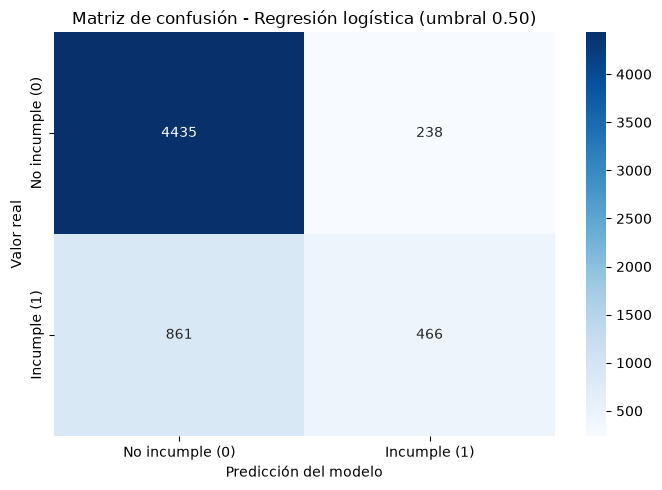

In [8]:

# ============================================================
# 4. EVALUACIÓN INICIAL DE LA REGRESIÓN LOGÍSTICA
# ============================================================

# Evaluar el modelo con el umbral predeterminado (0.50)
resultado_evaluacion = evaluar_modelo(
    modelo_logistico,
    X_test,
    y_test
)

# Mostrar las métricas obtenidas
print("MÉTRICAS DE EVALUACIÓN INICIAL")
print("--------------------------------")

for metrica, valor in resultado_evaluacion["metricas"].items():
    print(f"{metrica}: {valor:.4f}")

# Mostrar el informe de clasificación
print("\nINFORME DE CLASIFICACIÓN")
print("--------------------------------")
print(resultado_evaluacion["reporte"])

# ============================================================
# GRÁFICO DE LA MATRIZ DE CONFUSIÓN
# ============================================================

matriz = resultado_evaluacion["matriz_confusion"]

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No incumple (0)", "Incumple (1)"],
    yticklabels=["No incumple (0)", "Incumple (1)"]
)

plt.title("Matriz de confusión - Regresión logística (umbral 0.50)")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

### Interpretación de la evaluación inicial

La regresión logística, utilizando el umbral de clasificación predeterminado de 0.50, obtuvo un Accuracy de 81.68 %, una Precision de 66.19 %, un Recall de 35.12 % y un F1-score de 45.89 %.

Aunque el modelo presenta una proporción general de aciertos favorable, se observa una limitación importante en la identificación de los clientes que realmente incumplen sus obligaciones de pago.

El Recall de 35.12 % indica que el modelo logra identificar aproximadamente 35 de cada 100 clientes incumplidos. Esto evidencia que una parte importante de los casos de incumplimiento no está siendo detectada.

Por esta razón, se considera conveniente analizar diferentes umbrales de clasificación, buscando mejorar la capacidad del modelo para identificar a los clientes que podrían incumplir, sin perder de vista el equilibrio entre Precision y Recall.

In [9]:
# ============================================================
# 5. EVALUACIÓN DE LAS PROBABILIDADES DEL MODELO
# ============================================================

# Calcular ROC-AUC y Brier Score
resultado_probabilidades = evaluar_probabilidades(
    modelo_logistico,
    X_test,
    y_test
)

# Mostrar resultados
print("EVALUACIÓN DE PROBABILIDADES")
print("--------------------------------")

for metrica, valor in resultado_probabilidades.items():
    print(f"{metrica}: {valor:.4f}")

EVALUACIÓN DE PROBABILIDADES
--------------------------------
roc_auc: 0.7580
brier_score: 0.1387


### Interpretación de la evaluación de probabilidades

Además de revisar cuántos aciertos tuvo el modelo, también analizamos qué tan bien logra diferenciar a los clientes que podrían incumplir sus pagos de aquellos que sí cumplen.

El resultado del ROC-AUC fue de 0.7580. Esto nos indica que la regresión logística tiene una capacidad aceptable para distinguir entre los dos grupos de clientes.

Por otro lado, el Brier Score fue de 0.1387. Esta métrica nos permite conocer qué tan cercanas están las probabilidades calculadas por el modelo a lo que realmente sucede. En este caso, el resultado muestra un nivel de error relativamente bajo; recordemos que, cuanto más se acerque a cero, mejor.

En general, estos resultados nos ayudan a entender que el modelo no solo realiza predicciones, sino que también tiene una capacidad razonable para estimar la posibilidad de incumplimiento de los clientes.

In [10]:
# ============================================================
# 6. AJUSTE DEL UMBRAL DE CLASIFICACIÓN
# ============================================================

# Buscar el umbral que ofrece el mejor equilibrio entre
# Precision y Recall, utilizando los datos de entrenamiento
resultado_umbral = ajustar_umbral(
    modelo_logistico,
    X_train,
    y_train
)

# Recuperar el mejor umbral encontrado
mejor_umbral = resultado_umbral["mejor_umbral"]

# Recuperar los resultados de los diferentes umbrales
resultados_umbrales = resultado_umbral["resultados_umbrales"]

print("MEJOR UMBRAL DE CLASIFICACIÓN")
print("--------------------------------")
print(f"Umbral seleccionado: {mejor_umbral:.2f}")

print("\nCOMPARACIÓN DE UMBRALES")
print("--------------------------------")
display(resultados_umbrales)

MEJOR UMBRAL DE CLASIFICACIÓN
--------------------------------
Umbral seleccionado: 0.20

COMPARACIÓN DE UMBRALES
--------------------------------


,umbral,accuracy,precision,recall,f1
0,0.20,0.760000,0.467344,0.606403,0.527869
1,0.25,0.786875,0.517841,0.532957,0.525290
2,0.30,0.803125,0.564356,0.483051,0.520548
3,0.35,0.813542,0.610596,0.434087,0.507430
4,0.40,0.816458,0.635277,0.400188,0.491046
5,0.45,0.817083,0.654362,0.367232,0.470446
6,0.50,0.818333,0.677239,0.341808,0.454318


### Análisis de los diferentes umbrales de clasificación

Al comparar los resultados de los diferentes umbrales, encontramos que el valor de 0.20 obtuvo el mejor F1-score, con un resultado de 52.79 %.

Esto significa que, al reducir el umbral del 50 % al 20 %, el modelo logra identificar una mayor cantidad de clientes que podrían incumplir sus pagos. El Recall pasó de 34.18 % a 60.64 %, lo que representa una mejora importante en la detección de estos casos.

Sin embargo, esta mejora también tiene una consecuencia: la Precision disminuye de 67.72 % a 46.73 %. Esto quiere decir que aumentan los clientes que el modelo identifica como posibles incumplidos, pero que realmente no incumplen.

Teniendo en cuenta que para este proyecto es importante detectar la mayor cantidad posible de clientes con riesgo de incumplimiento, seleccionamos el umbral de 0.20, ya que obtuvo el mejor equilibrio entre Precision y Recall según el F1-score.

Es importante aclarar que esta selección se realizó utilizando los datos de validación, sin utilizar los datos de prueba para escoger el umbral.

In [11]:
# ============================================================
# 7. EVALUACIÓN DEL MODELO CON EL UMBRAL SELECCIONADO
# ============================================================

# Evaluar la regresión logística utilizando el umbral de 0.20
resultado_umbral_final = evaluar_con_umbral(
    modelo_logistico,
    X_test,
    y_test,
    mejor_umbral
)

# Mostrar las métricas obtenidas
print("MÉTRICAS DE EVALUACIÓN CON EL UMBRAL SELECCIONADO")
print("--------------------------------")

for metrica, valor in resultado_umbral_final["metricas"].items():
    print(f"{metrica}: {valor:.4f}")

# Mostrar el informe de clasificación
print("\nINFORME DE CLASIFICACIÓN")
print("--------------------------------")
print(resultado_umbral_final["reporte"])

MÉTRICAS DE EVALUACIÓN CON EL UMBRAL SELECCIONADO
--------------------------------
accuracy: 0.7515
precision: 0.4524
recall: 0.5870
f1: 0.5110

INFORME DE CLASIFICACIÓN
--------------------------------
              precision    recall  f1-score   support

           0       0.87      0.80      0.83      4673
           1       0.45      0.59      0.51      1327

    accuracy                           0.75      6000
   macro avg       0.66      0.69      0.67      6000
weighted avg       0.78      0.75      0.76      6000



### Evaluación final utilizando el umbral seleccionado

Después de seleccionar el umbral de 0.20, evaluamos nuevamente la regresión logística utilizando los datos de prueba.

Los resultados muestran que el modelo obtuvo un Accuracy de 75.15 %, una Precision de 45.24 %, un Recall de 58.70 % y un F1-score de 51.10 %.

Al comparar estos resultados con los obtenidos inicialmente con el umbral de 0.50, encontramos una mejora en la identificación de los clientes que realmente incumplen sus pagos. El Recall pasó de 35.12 % a 58.70 %, lo que significa que el modelo ahora logra detectar una mayor cantidad de estos casos.

Aunque la Precision y el Accuracy disminuyeron, el F1-score aumentó de 45.89 % a 51.10 %. Esto indica que conseguimos un mejor equilibrio entre la identificación de clientes incumplidos y la precisión de las predicciones.

Por lo tanto, consideramos que el umbral de 0.20 ofrece mejores resultados para el objetivo de nuestro proyecto, ya que permite detectar más clientes con riesgo de incumplimiento, aunque esto implique revisar algunos casos que finalmente no presentan incumplimiento.

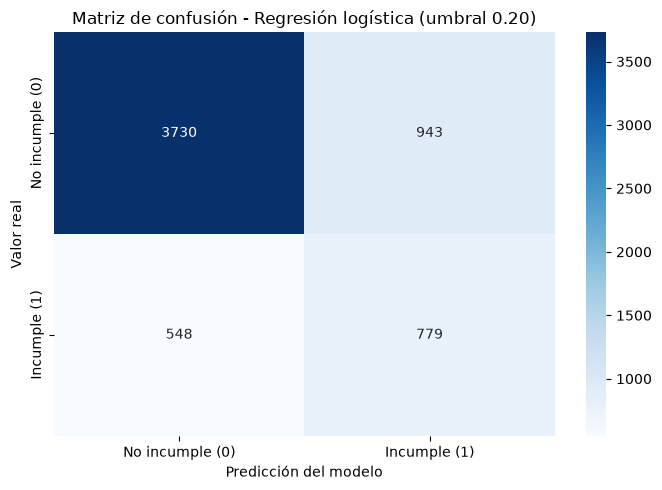

In [12]:
# ============================================================
# GRÁFICO DE LA MATRIZ DE CONFUSIÓN CON EL UMBRAL 0.20
# ============================================================

matriz_umbral = resultado_umbral_final["matriz_confusion"]

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz_umbral,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No incumple (0)", "Incumple (1)"],
    yticklabels=["No incumple (0)", "Incumple (1)"]
)

plt.title("Matriz de confusión - Regresión logística (umbral 0.20)")
plt.xlabel("Predicción del modelo")
plt.ylabel("Valor real")
plt.tight_layout()
plt.show()

### Interpretación de la matriz de confusión con el umbral 0.20

La matriz de confusión nos permite observar con mayor detalle cómo se comportó el modelo frente a los 6.000 registros de prueba.

De los clientes que realmente incumplieron sus pagos, el modelo logró identificar correctamente a 779, mientras que 548 casos no fueron detectados.

Por otro lado, identificó correctamente a 3.730 clientes que no incumplieron, aunque también señaló equivocadamente a 943 clientes como posibles incumplidos.

Estos resultados muestran que, al utilizar el umbral de 0.20, logramos detectar una mayor cantidad de clientes que incumplen sus obligaciones de pago. Sin embargo, también aumenta la cantidad de alertas incorrectas.

En conclusión, el nuevo umbral mejora la capacidad de detección del modelo, aunque sus resultados todavía presentan oportunidades de mejora, especialmente en la precisión de las predicciones.

In [14]:
# ============================================================
# 8. COMPARACIÓN DEL MODELO EN ENTRENAMIENTO Y PRUEBA
# ============================================================

# Evaluar el modelo con los datos de entrenamiento
resultado_entrenamiento_umbral = evaluar_con_umbral(
    modelo_logistico,
    X_train,
    y_train,
    mejor_umbral
)

# Recuperar las métricas de entrenamiento
metricas_entrenamiento = resultado_entrenamiento_umbral["metricas"]

# Recuperar las métricas de prueba
metricas_prueba = resultado_umbral_final["metricas"]

# Crear una tabla para comparar los resultados
comparacion_desempeno = pd.DataFrame({
    "Entrenamiento": metricas_entrenamiento,
    "Prueba": metricas_prueba
})

print("COMPARACIÓN DEL DESEMPEÑO DEL MODELO")
print("--------------------------------")
display(comparacion_desempeno)

COMPARACIÓN DEL DESEMPEÑO DEL MODELO
--------------------------------


,Entrenamiento,Prueba
accuracy,0.758500,0.751500
precision,0.465534,0.452381
recall,0.619514,0.587038
f1,0.531599,0.510987


### Análisis del sobreajuste (Overfitting)

Para revisar si el modelo presenta sobreajuste, comparamos sus resultados con los datos de entrenamiento y los datos de prueba, utilizando el umbral de clasificación de 0.20.

Al realizar esta comparación, encontramos que las métricas presentan diferencias pequeñas entre ambos conjuntos. Por ejemplo, el F1-score fue de 53.16 % en entrenamiento y de 51.10 % en prueba.

Esto nos indica que el modelo mantiene un comportamiento similar al trabajar con datos que ya utilizó para aprender y con datos que no había visto anteriormente.

No encontramos señales importantes de sobreajuste.

## 9. Conclusiones generales de la evaluación

Después de evaluar la regresión logística, encontramos que el modelo tiene capacidad para identificar clientes que podrían incumplir sus pagos, aunque todavía presenta algunas limitaciones.

Inicialmente trabajamos con el umbral de 0.50, pero observamos que el modelo identificaba pocos de los clientes que realmente incumplían. Por esta razón, comparamos diferentes umbrales y seleccionamos el de 0.20, ya que obtuvo el mejor resultado en F1-score durante la validación.

Al evaluar este nuevo umbral con los datos de prueba, obtuvimos un Recall de 58.70 % y un F1-score de 51.10 %. Esto significa que el modelo logró identificar aproximadamente 59 de cada 100 clientes que realmente incumplieron sus pagos.

Sin embargo, también encontramos que la Precision fue de 45.24 %, lo que indica que todavía se presentan bastantes alertas de clientes que finalmente no incumplen.

Por otra parte, al comparar los resultados de entrenamiento y prueba, no encontramos diferencias importantes, lo que nos da una señal favorable sobre la estabilidad del modelo y no muestra indicios importantes de sobreajuste.

En conclusión, consideramos que la regresión logística puede ser una herramienta de apoyo para identificar clientes con posibles riesgos de incumplimiento. No obstante, sus predicciones no deben tomarse como una decisión definitiva, sino como una señal que puede ayudar a orientar el análisis y el seguimiento de los clientes.
